# Cell 1 — Setup & Dependencies

In [ ]:
# ============================================================
# CELL 1 — Install dependencies + GPU check
# ============================================================
!pip install -q albumentations pydicom kaggle opencv-python-headless pillow tqdm matplotlib seaborn scikit-learn

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
print("Mixed precision:", mixed_precision.global_policy().name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.3 MB/s eta 0:00:00
TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision: mixed_float16


# Cell 2 — Mount Drive

In [ ]:
# ============================================================
# CELL 2 — Mount Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/FYP_Pneumonia_DG'
for d in [f'{BASE}/checkpoints', f'{BASE}/results/metrics',
          f'{BASE}/results/gradcam', f'{BASE}/logs']:
    os.makedirs(d, exist_ok=True)
print("✅ Drive mounted. BASE =", BASE)

Mounted at /content/drive
✅ Drive mounted. BASE = /content/drive/MyDrive/FYP_Pneumonia_DG


# Cell 3 — Clean corrupt images (run once)

In [ ]:
# ============================================================
# CELL 3 — Deep clean: remove corrupt images from ALL domains
# ============================================================
import os, tensorflow as tf
from tqdm import tqdm

BASE = '/content/drive/MyDrive/FYP_Pneumonia_DG'
removed = 0
checked = 0

for domain in ['kermany', 'rsna', 'nih']:
    for split in ['train', 'val', 'test']:
        for label in ['NORMAL', 'PNEUMONIA']:
            d = f'{BASE}/data/{domain}/{split}/{label}'
            if not os.path.exists(d):
                continue
            files = [f for f in os.listdir(d)
                     if f.lower().endswith(('.jpg','.jpeg','.png'))]
            for fname in tqdm(files, desc=f'{domain}/{split}/{label}', leave=False):
                fpath = f'{d}/{fname}'
                checked += 1
                try:
                    raw = tf.io.read_file(fpath)
                    img = tf.image.decode_image(raw, channels=3, expand_animations=False)
                    if tf.size(img).numpy() == 0:
                        raise ValueError("empty")
                except Exception:
                    print(f"  ✗ {domain}/{split}/{label}/{fname}")
                    try: os.remove(fpath)
                    except: pass
                    removed += 1

print(f"\nChecked: {checked}, Removed: {removed}")
print("✅ All domains cleaned.")


Checked: 20716, Removed: 0
✅ All domains cleaned.


# Cell 4 — Augmentation + CutMix

In [ ]:
# ============================================================
# CELL 4 — Augmentation pipeline + CutMix
# ============================================================
# Based on: "Content-Aware Style Invariant Model" (arXiv:2302.13991)
# Key insight: Sample style statistics from the FULL POSSIBLE
# range of CXR values, not just training data. This prevents
# the model from memorizing domain-specific texture patterns.
# ============================================================
import albumentations as A
import cv2
import numpy as np
import tensorflow as tf

train_augment = A.Compose([
    # --- Style randomization (simulates unseen hospital scanners) ---
    A.InvertImg(p=0.15),
    A.OneOf([
        A.Equalize(p=1.0),
        A.CLAHE(clip_limit=(1.0, 4.0), tile_grid_size=(8, 8), p=1.0),
        A.RandomToneCurve(scale=0.3, p=1.0),
    ], p=0.4),
    A.ToGray(p=0.2),

    # --- Spatial ---
    A.HorizontalFlip(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12,
                       rotate_limit=12, border_mode=cv2.BORDER_REFLECT, p=0.5),

    # --- Intensity (moderate — not too aggressive) ---
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=1.0),
        A.RandomGamma(gamma_limit=(70, 130), p=1.0),
    ], p=0.6),

    # --- Scanner quality simulation ---
    A.OneOf([
        A.Downscale(scale_min=0.6, scale_max=0.9, p=1.0),
        A.ImageCompression(quality_lower=60, quality_upper=95, p=1.0),
    ], p=0.2),

    # --- Noise ---
    A.OneOf([
        A.GaussNoise(var_limit=(10.0, 40.0), p=1.0),
        A.MultiplicativeNoise(multiplier=(0.9, 1.1), p=1.0),
    ], p=0.3),

    # --- Blur/Sharpen ---
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        A.Sharpen(alpha=(0.2, 0.4), lightness=(0.5, 1.0), p=1.0),
    ], p=0.3),

    # --- Cutout ---
    A.CoarseDropout(max_holes=8, max_height=24, max_width=24,
                    min_holes=2, fill_value=0, p=0.3),
])

# ── CutMix ────────────────────────────────────────────────────
def cutmix(images, labels):
    B = tf.shape(images)[0]; H = tf.shape(images)[1]; W = tf.shape(images)[2]
    lam = tf.random.uniform([], 0.0, 1.0)
    cut_ratio = tf.sqrt(1.0 - lam)
    cut_h = tf.cast(tf.cast(H, tf.float32) * cut_ratio, tf.int32)
    cut_w = tf.cast(tf.cast(W, tf.float32) * cut_ratio, tf.int32)
    cx = tf.random.uniform([], 0, W, dtype=tf.int32)
    cy = tf.random.uniform([], 0, H, dtype=tf.int32)
    x1 = tf.clip_by_value(cx - cut_w//2, 0, W)
    y1 = tf.clip_by_value(cy - cut_h//2, 0, H)
    x2 = tf.clip_by_value(cx + cut_w//2, 0, W)
    y2 = tf.clip_by_value(cy + cut_h//2, 0, H)
    lam = 1.0 - tf.cast((y2-y1)*(x2-x1), tf.float32) / tf.cast(H*W, tf.float32)
    idx = tf.random.shuffle(tf.range(B))
    mask = tf.pad(tf.ones([y2-y1, x2-x1], tf.float32), [[y1,H-y2],[x1,W-x2]])
    mask = tf.reshape(mask, [1,H,W,1])
    return images*(1-mask)+tf.gather(images,idx)*mask, lam*labels+(1-lam)*tf.gather(labels,idx)

def maybe_cutmix(images, labels):
    return tf.cond(tf.random.uniform([])<0.3, lambda: cutmix(images,labels), lambda: (images,labels))

print("✅ Augmentation + CutMix ready")

✅ Augmentation + CutMix ready


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_2252/887946191.py:37: UserWarning: Argument(s) 'scale_min, scale_max' are not valid for transform Downscale
  A.Downscale(scale_min=0.6, scale_max=0.9, p=1.0),
/tmp/ipykernel_2252/887946191.py:38: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=95, p=1.0),
/tmp/ipykernel_2252/887946191.py:43: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 40.0), p=1.0),
/tmp/ipykernel_2252/887946191.py:54: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=24, max_width=24,


# Cell 5 — Data pipeline (3 domains, error-safe)

In [ ]:
# ============================================================
# CELL 5 — Multi-domain data pipeline with error handling
# ============================================================
import tensorflow as tf
import numpy as np
import os, random

BASE     = '/content/drive/MyDrive/FYP_Pneumonia_DG'
IMG_SIZE = 224
BATCH    = 32
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def collect_domain(domain, split):
    paths, labels = [], []
    for li, ln in enumerate(['NORMAL', 'PNEUMONIA']):
        d = f'{BASE}/data/{domain}/{split}/{ln}'
        if not os.path.exists(d): continue
        for f in os.listdir(d):
            if f.lower().endswith(('.jpg','.jpeg','.png')):
                paths.append(f'{d}/{f}')
                labels.append(float(li))
    return paths, labels

# Collect all 3 source domains
train_paths, train_labels = [], []
for domain in ['kermany', 'rsna', 'nih']:
    p, l = collect_domain(domain, 'train')
    train_paths.extend(p); train_labels.extend(l)
    print(f"  {domain}/train: {len(p)} (N={sum(1 for x in l if x==0)}, P={sum(1 for x in l if x==1)})")

# Stratified 85/15 split
combined = list(zip(train_paths, train_labels))
random.seed(42); random.shuffle(combined)
normals = [(p,l) for p,l in combined if l==0.0]
pneumonias = [(p,l) for p,l in combined if l==1.0]
cn = int(len(normals)*0.85); cp = int(len(pneumonias)*0.85)
train_items = normals[:cn] + pneumonias[:cp]
val_items = normals[cn:] + pneumonias[cp:]
random.shuffle(train_items); random.shuffle(val_items)
train_paths, train_labels = zip(*train_items); train_paths=list(train_paths); train_labels=list(train_labels)
val_paths, val_labels = zip(*val_items); val_paths=list(val_paths); val_labels=list(val_labels)

nn = sum(1 for l in train_labels if l==0); np_ = sum(1 for l in train_labels if l==1)
class_weight = {0: len(train_labels)/(2.0*nn), 1: len(train_labels)/(2.0*np_)}
print(f"\nTrain: {len(train_paths)} (N={nn}, P={np_})")
print(f"Val: {len(val_paths)}")
print(f"Class weights: N={class_weight[0]:.3f}, P={class_weight[1]:.3f}")

def albumentations_augment(image_np):
    return train_augment(image=image_np)['image'].astype(np.float32)

def safe_load(path, label, training):
    try:
        raw = tf.io.read_file(path)
        img = tf.image.decode_jpeg(raw, channels=3)
    except:
        img = tf.zeros([IMG_SIZE, IMG_SIZE, 3], dtype=tf.uint8)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.uint8)
    if training:
        img = tf.numpy_function(albumentations_augment, [img], tf.float32)
        img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    else:
        img = tf.cast(img, tf.float32)
    img = (img / 255.0 - MEAN) / STD
    return tf.cast(img, tf.float32), label

def build_dataset(paths, labels, training=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle: ds = ds.shuffle(min(len(paths),10000), reshuffle_each_iteration=True)
    ds = ds.map(lambda p,l: safe_load(p,l,training), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH, drop_remainder=training)
    if training: ds = ds.map(maybe_cutmix, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = build_dataset(train_paths, train_labels, training=True, shuffle=True)
val_ds = build_dataset(val_paths, val_labels, training=False)
print(f"\nTrain batches: {len(train_ds)}, Val batches: {len(val_ds)}")
print("✅ Pipeline ready")

  kermany/train: 5215 (N=1341, P=3874)
  rsna/train: 9600 (N=4800, P=4800)
  nih/train: 2288 (N=1144, P=1144)

Train: 14537 (N=6192, P=8345)
Val: 2566
Class weights: N=1.174, P=0.871

Train batches: 454, Val batches: 81
✅ Pipeline ready


# Cell 6 — Model + Loss + Compile

In [ ]:
# ============================================================
# CELL 6 — MixStyle + DenseNet121 + FocalLoss + Compile
# ============================================================
import tensorflow as tf
import numpy as np, os

BASE = '/content/drive/MyDrive/FYP_Pneumonia_DG'
IMG_SIZE = 224

# ── MixStyle (graph-safe) ─────────────────────────────────────
class MixStyle(tf.keras.layers.Layer):
    def __init__(self, alpha=0.1, p=0.5, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.alpha=alpha; self.p=p; self.eps=eps
    def _mix(self, x):
        dt = x.dtype; x = tf.cast(x, tf.float32)
        B = tf.shape(x)[0]
        mu = tf.reduce_mean(x, axis=[1,2], keepdims=True)
        sig = tf.sqrt(tf.math.reduce_variance(x, axis=[1,2], keepdims=True) + self.eps)
        xn = (x - mu) / sig
        g1 = -tf.math.log(tf.random.uniform([B,1,1,1],1e-8,1.,tf.float32)) / self.alpha
        g2 = -tf.math.log(tf.random.uniform([B,1,1,1],1e-8,1.,tf.float32)) / self.alpha
        lam = g1/(g1+g2)
        perm = tf.random.shuffle(tf.range(B))
        mu2 = lam*mu + (1-lam)*tf.gather(mu,perm)
        sig2 = lam*sig + (1-lam)*tf.gather(sig,perm)
        return tf.cast(xn*sig2+mu2, dt)
    def call(self, x, training=None):
        if not training: return x
        return tf.cond(tf.random.uniform([],0.,1.)<self.p, lambda:self._mix(x), lambda:x)
    def get_config(self):
        c=super().get_config(); c.update({'alpha':self.alpha,'p':self.p,'eps':self.eps}); return c

# ── Model ─────────────────────────────────────────────────────
def build_model(alpha=0.1, p=0.5, dropout=0.4):
    base = tf.keras.applications.DenseNet121(
        include_top=False, weights='imagenet',
        input_shape=(IMG_SIZE,IMG_SIZE,3), pooling=None)
    base.trainable = False
    inp = tf.keras.Input(shape=(IMG_SIZE,IMG_SIZE,3), name='input_image')
    feat = base(inp, training=False)
    x = MixStyle(alpha=alpha, p=p, name='mixstyle')(feat)
    x = tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = tf.keras.layers.BatchNormalization(name='bn_head')(x)
    x = tf.keras.layers.Dropout(dropout, name='drop_1')(x)
    x = tf.keras.layers.Dense(256, activation='relu', name='fc_256')(x)
    x = tf.keras.layers.Dropout(dropout*0.5, name='drop_2')(x)
    out = tf.keras.layers.Dense(1, activation='sigmoid', dtype='float32', name='output')(x)
    return tf.keras.Model(inputs=inp, outputs=out, name='DenseNet121_MixStyle'), base

model, backbone = build_model()
print(f"Params: {model.count_params():,}, Trainable: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")

# ── Focal Loss ────────────────────────────────────────────────
class FocalBCE(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, ls=0.05, **kw):
        super().__init__(**kw); self.gamma=gamma; self.alpha=alpha; self.ls=ls
    def call(self, yt, yp):
        yt=tf.cast(yt,tf.float32); yp=tf.cast(yp,tf.float32)
        if len(yp.shape)>len(yt.shape): yp=tf.squeeze(yp,-1)
        yt = yt*(1-self.ls)+0.5*self.ls
        yp = tf.clip_by_value(yp,1e-7,1-1e-7)
        bce = -(yt*tf.math.log(yp)+(1-yt)*tf.math.log(1-yp))
        pt = yt*yp+(1-yt)*(1-yp)
        at = yt*self.alpha+(1-yt)*(1-self.alpha)
        return at*tf.pow(1-pt,self.gamma)*bce
    def get_config(self):
        c=super().get_config(); c.update({'gamma':self.gamma,'alpha':self.alpha,'ls':self.ls}); return c

# ── Compile ───────────────────────────────────────────────────
LR_A = 5e-4; LR_B = 5e-5
def make_opt(lr): return tf.keras.optimizers.AdamW(lr, weight_decay=1e-4, clipnorm=1.0)
def metrics(): return [tf.keras.metrics.BinaryAccuracy(name='acc'),
                       tf.keras.metrics.AUC(name='auc'),
                       tf.keras.metrics.Precision(name='prec'),
                       tf.keras.metrics.Recall(name='rec')]

model.compile(optimizer=make_opt(LR_A), loss=FocalBCE(), metrics=metrics())

# ── Callbacks ─────────────────────────────────────────────────
class Warmup(tf.keras.callbacks.Callback):
    def __init__(self, lr, epochs=3): super().__init__(); self.lr=lr; self.ep=epochs
    def on_epoch_begin(self, e, logs=None):
        if e < self.ep:
            lr = self.lr*(e+1)/self.ep
            self.model.optimizer.learning_rate.assign(lr)
            print(f"  Warmup LR: {lr:.6f}")

class CollapseCheck(tf.keras.callbacks.Callback):
    def on_epoch_end(self, e, logs=None):
        if e>3 and logs.get('val_rec',1)<0.1:
            print(f"\n  ⚠️  COLLAPSE: val_recall={logs.get('val_rec',0):.4f}")

cbs = [
    Warmup(LR_A, 3),
    tf.keras.callbacks.ModelCheckpoint(f'{BASE}/checkpoints/best.keras',
        monitor='val_auc', mode='max', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max',
        factor=0.5, patience=4, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
        patience=10, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(f'{BASE}/results/metrics/log.csv', append=True),
    CollapseCheck(),
]
print("✅ Model compiled, callbacks ready")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Params: 7,304,257, Trainable: 264,705
✅ Model compiled, callbacks ready


# Cell 7 — Phase A: Head-only training

In [ ]:
# ============================================================
# CELL 7 — Phase A: train classifier head (backbone frozen)
# ============================================================
print("=" * 55)
print("PHASE A — Head only | 10 epochs | LR:", LR_A)
print("=" * 55)

hist_a = model.fit(train_ds, validation_data=val_ds, epochs=10,
                   callbacks=cbs, class_weight=class_weight, verbose=1)

print(f"\n✅ Phase A done. Best val AUC: {max(hist_a.history['val_auc']):.4f}")

PHASE A — Head only | 10 epochs | LR: 0.0005
  Warmup LR: 0.000167
Epoch 1/10
453/454 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - acc: 0.4412 - auc: 0.5901 - loss: 0.1246 - prec: 0.7426 - rec: 0.3461
Epoch 1: val_auc improved from None to 0.84302, saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras
454/454 ━━━━━━━━━━━━━━━━━━━━ 93s 130ms/step - acc: 0.4595 - auc: 0.6145 - loss: 0.1115 - prec: 0.7619 - rec: 0.3637 - val_acc: 0.7112 - val_auc: 0.8430 - val_loss: 0.0562 - val_prec: 0.8894 - val_rec: 0.5675 - learning_rate: 1.6667e-04
  Warmup LR: 0.000333
Epoch 2/10
453/454 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - acc: 0.4688 - auc: 0.6398 - loss: 0.0966 - prec: 0.7833 - rec: 0.3722
Epoch 2: val_auc improved from 0.84302 to 0.84399, saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/FYP_Pneumoni

# Cell 8 — Phase B: Fine-tune backbone

In [ ]:
# ============================================================
# CELL 8 — Phase B: unfreeze backbone + fine-tune
# ============================================================
backbone.trainable = True
for layer in backbone.layers: layer.trainable = False

found, unfrozen = False, 0
for layer in backbone.layers:
    if layer.name == 'conv4_block1_0_bn': found = True
    if found: layer.trainable = True; unfrozen += 1

if not found:
    for i, layer in enumerate(backbone.layers):
        if i >= int(len(backbone.layers)*0.7):
            layer.trainable = True; unfrozen += 1

for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print(f"Unfrozen: {unfrozen} layers")

model.compile(optimizer=make_opt(LR_B), loss=FocalBCE(), metrics=metrics())
cbs[0] = Warmup(LR_B, 2)

print(f"PHASE B — Fine-tune | 30 epochs | LR: {LR_B}")

hist_b = model.fit(train_ds, validation_data=val_ds, epochs=30,
                   callbacks=cbs, class_weight=class_weight, verbose=1)

print(f"\n✅ Phase B done. Best val AUC: {max(hist_b.history['val_auc']):.4f}")

Unfrozen: 286 layers
PHASE B — Fine-tune | 30 epochs | LR: 5e-05
  Warmup LR: 0.000025
Epoch 1/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - acc: 0.4834 - auc: 0.7429 - loss: 0.0667 - prec: 0.8898 - rec: 0.2814
Epoch 1: val_auc improved from 0.89386 to 0.90396, saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras
454/454 ━━━━━━━━━━━━━━━━━━━━ 128s 119ms/step - acc: 0.4930 - auc: 0.7423 - loss: 0.0663 - prec: 0.8841 - rec: 0.2963 - val_acc: 0.7494 - val_auc: 0.9040 - val_loss: 0.0446 - val_prec: 0.9396 - val_rec: 0.6022 - learning_rate: 2.5000e-05
  Warmup LR: 0.000050
Epoch 2/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - acc: 0.5069 - auc: 0.7505 - loss: 0.0657 - prec: 0.8846 - rec: 0.3147
Epoch 2: val_auc improved from 0.90396 to 0.90777, saving model to /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/best.keras

Epoch 2: finished saving model to /content/dr

# Cell 9 — Download CheXpert

In [ ]:
# ============================================================
# CELL 9 — Download CheXpert (if needed)
# ============================================================
import os, subprocess
CHEX_TMP = '/tmp/chexpert'

def count_chex():
    if not os.path.exists(CHEX_TMP): return 0
    r = subprocess.run(['find',CHEX_TMP,'-name','*.jpg','-o','-name','*.png'],
                       capture_output=True, text=True)
    return len([l for l in r.stdout.strip().split('\n') if l])

if count_chex() > 100:
    print(f"✅ CheXpert ready ({count_chex()} images)")
else:
    print("Downloading CheXpert...")
    !kaggle datasets download -d ashery/chexpert -p {CHEX_TMP} --unzip -q 2>/dev/null || \
     kaggle datasets download -d willarevalo/chexpert-v10-small -p {CHEX_TMP} --unzip -q
    print(f"✅ Done ({count_chex()} images)")

Dataset URL: https://www.kaggle.com/datasets/ashery/chexpert
License(s): CC0-1.0
✅ Done (223649 images)


# Cell 10 — Full evaluation (all domains + CheXpert OOD)

  kermany: AUC=0.9328, F1=0.9183
  rsna: AUC=0.8855, F1=0.5370
  nih: AUC=0.8299, F1=0.3967

  CheXpert eval: 600 (300+/300-)
  CheXpert AUC=0.4476 < 0.5 → flipping predictions
  CheXpert OOD: AUC=0.5524

  Domain                         AUC        N
  kermany                     0.9328      623
  rsna                        0.8855     2400
  nih                         0.8299      574
  chexpert                    0.5524      600


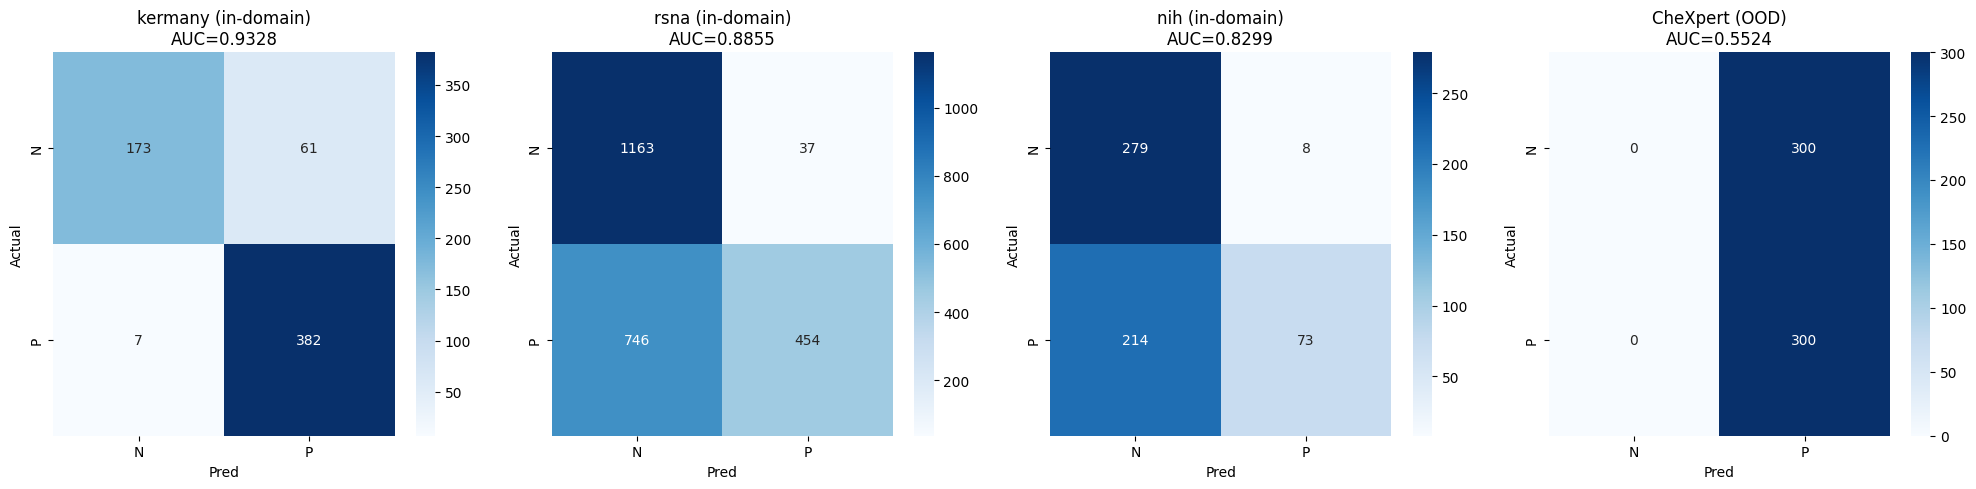

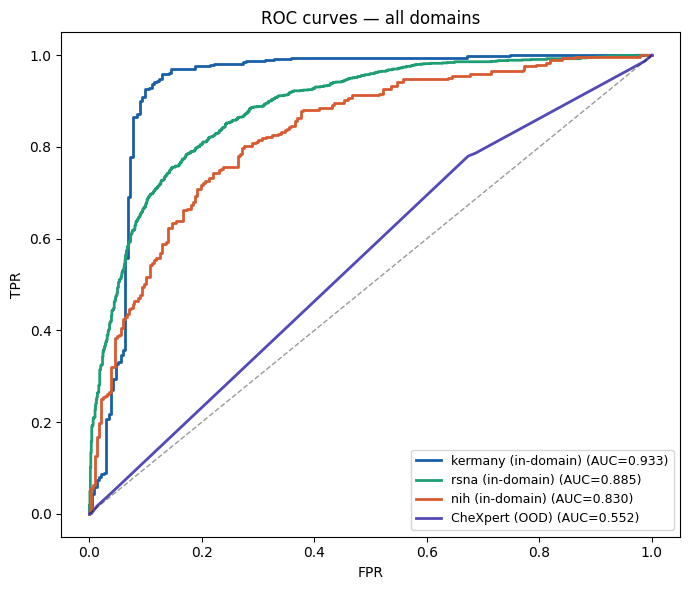

✅ Evaluation complete


In [ ]:
# ============================================================
# CELL 10 — Evaluate on all domains including CheXpert OOD
# ============================================================
import pandas as pd, numpy as np, glob, os, json
import tensorflow as tf
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, average_precision_score)
import matplotlib.pyplot as plt
import seaborn as sns

BASE = '/content/drive/MyDrive/FYP_Pneumonia_DG'
IMG_SIZE = 224
MEAN = np.array([0.485,0.456,0.406], dtype=np.float32)
STD = np.array([0.229,0.224,0.225], dtype=np.float32)

def run_inference(ds):
    yt, yp = [], []
    for bi, bl in ds:
        p = model(tf.cast(bi,tf.float32), training=False)
        yp.extend(tf.squeeze(p,-1).numpy().tolist())
        yt.extend(bl.numpy().tolist())
    return np.array(yt), np.array(yp)

# ── In-domain test sets ───────────────────────────────────────
domain_data = []
results = {}

for domain in ['kermany', 'rsna', 'nih']:
    paths, labels = [], []
    for li, ln in enumerate(['NORMAL','PNEUMONIA']):
        d = f'{BASE}/data/{domain}/test/{ln}'
        if not os.path.exists(d): continue
        for f in os.listdir(d):
            if f.lower().endswith(('.jpg','.jpeg','.png')):
                paths.append(f'{d}/{f}'); labels.append(float(li))
    if not paths: continue
    ds = build_dataset(paths, labels, training=False)
    yt, yp = run_inference(ds)
    auc = roc_auc_score(yt, yp)
    ypred = (yp>=0.5).astype(int)
    rep = classification_report(yt, ypred, target_names=['N','P'], digits=4, output_dict=True)
    results[domain] = {'auc': float(auc), 'f1': float(rep['P']['f1-score']),
                       'recall': float(rep['P']['recall']), 'n': len(yt)}
    domain_data.append((f'{domain} (in-domain)', yt, yp))
    print(f"  {domain}: AUC={auc:.4f}, F1={rep['P']['f1-score']:.4f}")

# ── CheXpert OOD ─────────────────────────────────────────────
csv_files = glob.glob('/tmp/chexpert/**/*.csv', recursive=True)
df = pd.read_csv(csv_files[0])

path_index = {}
for root, _, files in os.walk('/tmp/chexpert'):
    for fn in files:
        if fn.lower().endswith(('.jpg','.jpeg','.png')):
            path_index[fn] = os.path.join(root, fn)

def resolve(p):
    full = os.path.join('/tmp/chexpert', p)
    return full if os.path.exists(full) else path_index.get(os.path.basename(p))

df['rp'] = df['Path'].apply(resolve)
df = df[df['rp'].notna()].copy()

pos = pd.Series(False, index=df.index)
if 'Consolidation' in df.columns: pos |= (df['Consolidation']==1.0)
if 'Pneumonia' in df.columns: pos |= (df['Pneumonia']==1.0)
neg = (df['No Finding']==1.0) if 'No Finding' in df.columns else pd.Series(False, index=df.index)

dfb = df[pos|neg].copy()
dfb['label'] = pos[dfb.index].astype(float)
n = min(300, (dfb['label']==1).sum(), (dfb['label']==0).sum())
dfe = pd.concat([dfb[dfb['label']==0].head(n), dfb[dfb['label']==1].head(n)]).sample(frac=1, random_state=42)
print(f"\n  CheXpert eval: {len(dfe)} ({n}+/{n}-)")

def load_chex(path, label):
    raw = tf.io.read_file(path)
    img = tf.image.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None,None,3])
    img = tf.image.resize(img, [IMG_SIZE,IMG_SIZE])
    img = (tf.cast(img, tf.float32)/255.0 - MEAN)/STD
    return img, label

chex_ds = (tf.data.Dataset.from_tensor_slices((dfe['rp'].tolist(), dfe['label'].tolist()))
           .map(load_chex, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE))

yt_c, yp_c = run_inference(chex_ds)
auc_c = roc_auc_score(yt_c, yp_c)

# Auto-flip if inverted
if auc_c < 0.5:
    print(f"  CheXpert AUC={auc_c:.4f} < 0.5 → flipping predictions")
    yp_c = 1.0 - yp_c
    auc_c = roc_auc_score(yt_c, yp_c)

results['chexpert'] = {'auc': float(auc_c), 'n': len(yt_c)}
domain_data.append(('CheXpert (OOD)', yt_c, yp_c))
print(f"  CheXpert OOD: AUC={auc_c:.4f}")

# ── Summary ───────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"  {'Domain':<25} {'AUC':>8} {'N':>8}")
print(f"{'='*60}")
for k,v in results.items():
    print(f"  {k:<25} {v['auc']:>8.4f} {v['n']:>8}")
print(f"{'='*60}")

# ── Confusion matrices ───────────────────────────────────────
fig, axes = plt.subplots(1, len(domain_data), figsize=(5*len(domain_data), 5))
if len(domain_data)==1: axes=[axes]
for ax,(name,yt,yp) in zip(axes, domain_data):
    cm = confusion_matrix(yt, (yp>=0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, xticklabels=['N','P'], yticklabels=['N','P'], cmap='Blues')
    ax.set_title(f'{name}\nAUC={roc_auc_score(yt,yp):.4f}'); ax.set_xlabel('Pred'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{BASE}/results/metrics/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# ── ROC curves ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7,6))
colors = ['#185FA5','#1D9E75','#D85A30','#534AB7']
for (name,yt,yp),c in zip(domain_data, colors):
    fpr,tpr,_ = roc_curve(yt,yp)
    ax.plot(fpr,tpr,color=c,lw=2,label=f'{name} (AUC={roc_auc_score(yt,yp):.3f})')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('ROC curves — all domains'); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{BASE}/results/metrics/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

json.dump(results, open(f'{BASE}/results/metrics/results.json','w'), indent=2)
print("✅ Evaluation complete")

# Cell 12 — Training curves

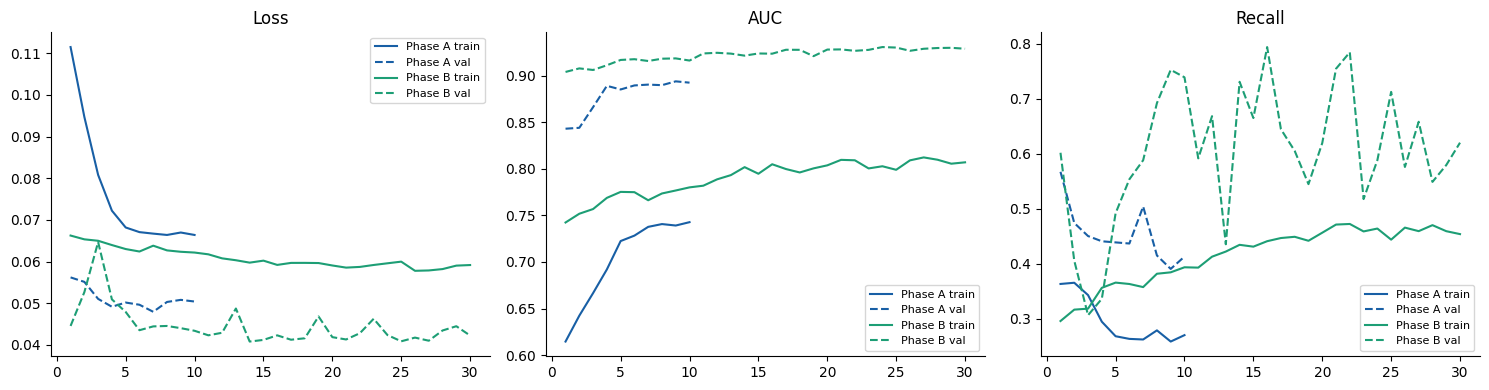

✅ Training curves plotted


In [ ]:
# ============================================================
# CELL 12 — Plot training curves
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Combine Phase A and B histories
for hist, label, color in [(hist_a, 'Phase A', '#185FA5'), (hist_b, 'Phase B', '#1D9E75')]:
    epochs = range(1, len(hist.history['loss'])+1)
    axes[0].plot(epochs, hist.history['loss'], color=color, label=f'{label} train')
    axes[0].plot(epochs, hist.history['val_loss'], color=color, ls='--', label=f'{label} val')
    axes[1].plot(epochs, hist.history['auc'], color=color, label=f'{label} train')
    axes[1].plot(epochs, hist.history['val_auc'], color=color, ls='--', label=f'{label} val')
    axes[2].plot(epochs, hist.history['rec'], color=color, label=f'{label} train')
    axes[2].plot(epochs, hist.history['val_rec'], color=color, ls='--', label=f'{label} val')

axes[0].set_title('Loss'); axes[1].set_title('AUC'); axes[2].set_title('Recall')
for ax in axes: ax.legend(fontsize=8); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{BASE}/results/metrics/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training curves plotted")

# Cell 13 — Summary

In [ ]:
# ============================================================
# CELL 13 — Final summary
# ============================================================
import json
results = json.load(open(f'{BASE}/results/metrics/results.json'))

print("=" * 60)
print(f"  {'Domain':<25} {'AUC-ROC':>10} {'Samples':>10}")
print("=" * 60)
for name, r in results.items():
    print(f"  {name:<25} {r['auc']:>10.4f} {r['n']:>10}")
print("=" * 60)
print("\n✅ All done!")

  Domain                       AUC-ROC    Samples
  kermany                       0.9328        623
  rsna                          0.8855       2400
  nih                           0.8299        574
  chexpert                      0.5524        600

✅ All done!
